# XL330 → surgical insertion

Apply the marked equation, then change one gain at a time.
Press **S** to end the loop and turn torque off. For simulation, focus the
PyBullet window first. Plots appear automatically. Do not use Esc.

## Connect

Set the serial port, baud and motor ID(s).

In [17]:
import dxl_utils as dxl

lab = dxl.connect("COM8", station="S", baud=1_000_000,
                  leader=2, demo=False, tissue="bone")

S: COM8; torque off. Gains/output use leader A; insertion follower N and m. Run one experiment cell.


## $u_F=k_p(x_d-x_F)-k_d\dot x_F$

Move the surgical instrument with the leader; no hand feedback.

**Change:** `kp`: 250 → 500 → 750; `kd`: 5 → 10. `T`: 0.001 → 0.005 → 0.010.

In [ ]:
T = 0.010  # seconds; then compare 0.005 and 0.010
kp, kd, scale = 750, 10, 0.04
with lab.run("1_unilateral", leader="off", tissue="bone", dt=T) as run:
    while run.active:
        L, F = run.read()
        xdes = max(-0.02, min(0.06, scale*L.q))
        uF = kp * (L.x - F.x) - kd* F.xdot 
        run.write(follower=uF, target=xdes)
        run.wait()

1_unilateral: target 100 Hz (T=10 ms). Focus PyBullet and press S; torque off and plots follow.


## $u_L=\beta\min(F_{\mathrm{contact}},0)$

Feel compression and release on withdrawal. The follower controller is provided.

**Change:** `beta`: 0.005 → 0.01 → 0.02. Then `tissue`: `"bone"` → `"liver"`, with gains unchanged.

2_contact_feedback: target 1000 Hz (T=1 ms). Focus PyBullet and press S; torque off and plots follow.
S: stopped normally; torque off.
Requested 1000 Hz (1 ms); achieved 572 Hz. Period mean/p99/max: 1.748/2.785/7.674 ms; jitter SD: 0.291 ms; skipped periods: 8341; work over budget: 11155 cycles.
2_contact_feedback_3 {'tracking_rmse_m': 0.0007651543930601811, 'max_error_m': 0.02}


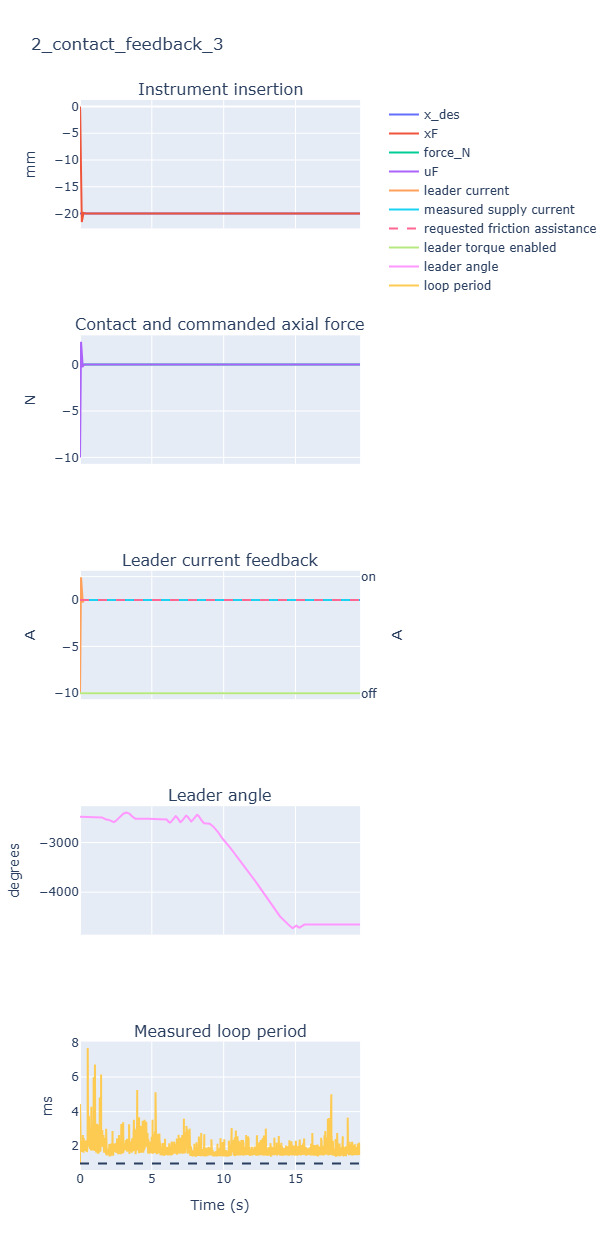

In [14]:
T = 0.001
beta, tissue = 0.01, "bone"
gate = dxl.ContactGate()  # provided contact/release scaffold
with lab.run("2_contact_feedback", leader="contact", tissue=tissue, dt=T) as run:
    while run.active:
        L, F = run.read()
        xdes = max(-0.02, min(0.06, 0.04*L.q))
        uF = 500*(xdes - F.x) - 10*F.xdot  # provided follower controller
        uL = beta * min(F.force, 0)
        run.write(leader=uL, follower=uF, target=xdes, leader_enabled=gate(L.v, F.force))
        run.wait()

## Disconnect

In [ ]:
lab.close()